# Drug-selection knapsack

Compare dynamic programming, branch and bound, and simulated QAOA on the same candidates. Run from top to bottom. Change the row selection and budget in **Shared inputs** for your next run.

In [5]:
# Run once in a fresh environment.
%pip install "qiskit>=2.4,<3" "qiskit-addon-opt-mapper>=0.1,<0.2" numpy pandas matplotlib "scipy>=1.16"

Note: you may need to restart the kernel to use updated packages.


## 1. Shared inputs

Put `Dataset.csv` next to the notebook, or set `CSV_PATH` to its location after mounting Drive in Colab. The notebook keeps the full DataFrame and selects the first `N_DRUGS` rows once. Costs and budget are integer millions, and expected values use up to two decimal places. By default the budget is 40% of the selected candidates' total testing cost, rounded down.

In [ ]:
from time import perf_counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from qiskit.circuit.library import qaoa_ansatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_addon_opt_mapper.applications import Knapsack
from qiskit_addon_opt_mapper.converters import OptimizationProblemToQubo
from qiskit_addon_opt_mapper.translators import to_ising
from scipy.optimize import minimize

CSV_PATH = "Dataset.csv"
N_DRUGS = 5
BUDGET = None  # Set an integer in $M to override the default.
QAOA_LAYERS = 1
SHOTS = 2_000

csv_path = Path(CSV_PATH).expanduser()
if not csv_path.is_absolute():
    candidates = [Path.cwd() / csv_path, Path.cwd() / "drug_selection" / csv_path]
    csv_path = next((path for path in candidates if path.is_file()), candidates[0])

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()
dataset = df.head(N_DRUGS)

names = dataset["Drugs"].tolist()
costs = dataset["Test Cost ($M)"].tolist()
values = dataset["Expected value ($M)"].tolist()
budget = int(0.4 * sum(costs)) if BUDGET is None else BUDGET

print(f"{len(dataset)} candidates | Budget: ${budget}M")
display(dataset[["Drugs", "Test Cost ($M)", "Expected value ($M)"]])

5 candidates | Budget: $12M


,Drugs,Test Cost ($M),Expected value ($M)
0,Drug_1,10,30.09
1,Drug_2,3,24.00
2,Drug_3,4,28.35
3,Drug_4,9,8.70
4,Drug_5,4,11.89


## 2. Classical solvers

Dynamic programming builds a table of best values for each budget. Branch and bound prunes branches using a fractional-knapsack upper bound. Both return the row indices of an optimal selection.

In [7]:
def dynamic_programming(costs, values, budget):
    n = len(costs)
    dp = [[0.0] * (budget + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        cost = int(costs[i - 1])
        value = float(values[i - 1])
        for b in range(budget + 1):
            dp[i][b] = dp[i - 1][b]
            if cost <= b:
                dp[i][b] = max(
                    dp[i][b],
                    value + dp[i - 1][b - cost]
                )
    selected = []
    b = budget
    for i in range(n, 0, -1):
        if dp[i][b] > dp[i - 1][b] + 1e-9:
            selected.append(i - 1)
            b -= costs[i - 1]

    return selected[::-1]

In [8]:
def branch_and_bound(costs, values, budget):
    n = len(costs)
    items = sorted(
        range(n),
        key=lambda i: values[i] / costs[i],
        reverse=True
    )

    best_value = 0.0
    best_selection = []

    def upper_bound(index, current_cost, current_value):
        remaining_budget = budget - current_cost
        bound = current_value

        for j in range(index, n):
            i = items[j]
            if costs[i] <= remaining_budget:
                remaining_budget -= costs[i]
                bound += values[i]
            else:
                bound += values[i] * remaining_budget / costs[i]
                break
        return bound

    def search(index, current_cost, current_value, selected):
        nonlocal best_value, best_selection
        if current_cost > budget:
            return
        if current_value > best_value:
            best_value = current_value
            best_selection = selected.copy()
        if index == n:
            return
        if upper_bound(index, current_cost, current_value) <= best_value:
            return

        i = items[index]
        search(
            index + 1,
            current_cost + costs[i],
            current_value + values[i],
            selected + [i]
        )

        search(
            index + 1,
            current_cost,
            current_value,
            selected
        )

    search(0, 0, 0.0, [])

    return sorted(best_selection)

## 3. QAOA solver

The mapper turns the budget constraint into a QUBO penalty, then maps that cost to a Hamiltonian. QAOA alternates cost phases with a mixer that changes measurement probabilities. COBYLA tunes the angles using exact simulated energy expectations. We then draw a finite number of simulated shots and return the highest-value selection observed within budget.

We divide the Hamiltonian by its largest absolute coefficient so the initial cost angles are on a manageable scale. The rescaling preserves the ordering of the encoded costs.

[Qiskit Optimization Mapper](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/02_converters_for_optimization_problems.html) · [QAOA circuit](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.qaoa_ansatz)

In [9]:
def solve_qaoa(costs, values, budget, *, layers=1, shots=2_000, seed=42):
    # Map knapsack to an Ising Hamiltonian.
    problem = Knapsack(
        values=[round(100 * value) for value in values],
        weights=list(costs),
        max_weight=budget,
    ).to_optimization_problem()
    converter = OptimizationProblemToQubo()
    hamiltonian, _ = to_ising(converter.convert(problem))
    if hamiltonian.num_qubits > 20:
        raise ValueError("Reduce the candidate count or budget for local simulation.")
    scale = float(np.max(np.abs(hamiltonian.coeffs))) or 1.0
    hamiltonian = hamiltonian / scale

    # Fit the circuit angles.
    circuit = qaoa_ansatz(hamiltonian, reps=layers)
    estimator = StatevectorEstimator()

    def mean_energy(angles):
        result = estimator.run([(circuit, hamiltonian, angles)]).result()[0]
        return result.data.evs.item()

    rng = np.random.default_rng(seed)
    initial = rng.uniform(0.1, 1.0, size=circuit.num_parameters)
    fit = minimize(
        mean_energy, initial, method="COBYLA",
        options={"maxiter": 150, "rhobeg": 0.25},
    )

    # Sample once and keep the best feasible selection.
    measured = circuit.assign_parameters(fit.x)
    measured.measure_all()
    sampler = StatevectorSampler(seed=seed)
    counts = sampler.run([measured], shots=shots).result()[0].data.meas.get_counts()

    best_selection, best_value = None, -np.inf
    for bitstring in counts:
        # Qiskit displays the highest-index qubit first.
        bits = [int(bit) for bit in reversed(bitstring)]
        selected = np.flatnonzero(converter.interpret(bits)).tolist()
        cost = sum(costs[i] for i in selected)
        value = sum(values[i] for i in selected)
        if cost <= budget and value > best_value:
            best_selection, best_value = selected, value

    return best_selection

## 4. Run and compare

Each solver takes the same `costs`, `values`, and `budget`. It returns selected row indices. An empty list is a valid selection, while `None` means QAOA sampled no feasible selection. One helper times each solver and builds a row for the table.

QAOA timing covers model mapping, circuit construction, fitting, sampling, and decoding on a classical statevector simulator. All timings exclude CSV loading, imports, and display.

In [10]:
def run_solver(method, solver, costs, values, names, budget, **options):
    start = perf_counter()
    selected = solver(costs, values, budget, **options)
    time_ms = 1_000 * (perf_counter() - start)

    drugs, cost, value = None, None, None
    if selected is not None:
        drugs = [names[i] for i in selected]
        cost = sum(costs[i] for i in selected)
        value = sum(values[i] for i in selected)

    return {
        "Method": method,
        "Selected drugs": drugs,
        "Cost ($M)": cost,
        "Expected value ($M)": value,
        "Time (ms)": time_ms,
    }


inputs = (costs, values, names, budget)
comparison = pd.DataFrame([
    run_solver("Dynamic programming", dynamic_programming, *inputs),
    run_solver("Branch and bound", branch_and_bound, *inputs),
    run_solver("QAOA (simulated)", solve_qaoa, *inputs, layers=QAOA_LAYERS, shots=SHOTS),
]).set_index("Method")

display(comparison.round({"Expected value ($M)": 2, "Time (ms)": 4}))

,Selected drugs,Cost ($M),Expected value ($M),Time (ms)
Method,,,,
Dynamic programming,"[Drug_2, Drug_3, Drug_5]",11,64.24,0.0181
Branch and bound,"[Drug_2, Drug_3, Drug_5]",11,64.24,0.0154
QAOA (simulated),"[Drug_2, Drug_3, Drug_5]",11,64.24,236.0268


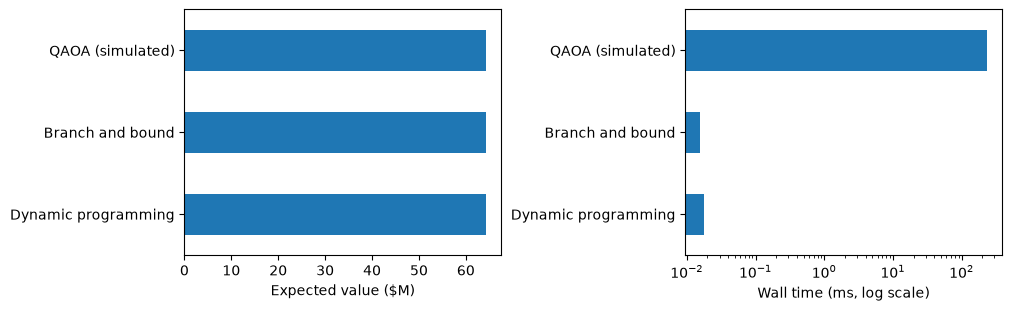

In [11]:
fig, (quality, runtime) = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
comparison["Expected value ($M)"].dropna().plot.barh(ax=quality)
comparison["Time (ms)"].plot.barh(ax=runtime, logx=True)
quality.set(xlabel="Expected value ($M)", ylabel="")
runtime.set(xlabel="Wall time (ms, log scale)", ylabel="")
plt.show()